# IND320 Project Part 3 – Data quality
## Reservoir seasonality and weather anomalies

**Author:** Daniar Omar

This notebook extends Parts 1 and 2 with official NVE geographical regions, reproducible point sampling, ERA5 weather retrieval and four analyses: DCT/SPC, Local Outlier Factor, STL and a spectrogram.

**GitHub:** https://github.com/dano22222/dano22222

**Streamlit application (same app as Parts 1 and 2):** https://dano22222-u9jpvjhwntlcuukcush85v.streamlit.app/

**Screencast of the assignment:** ADD GOOGLE DRIVE LINK HERE

## 1. Environment and configuration

The analysis and download functions live in the `src/` package, so the notebook and the Streamlit app use exactly the same code. Their full source code is printed in the appendix. Weather timestamps use UTC, which avoids daylight-saving gaps.

In [1]:
#locate the project from either the root or the notebooks folder
from pathlib import Path
import sys, json, importlib.metadata
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

#standard libraries for data handling and plotting
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

#project functions shared with the streamlit app
from src.analysis import spc_analysis, lof_analysis, stl_analysis, spectrogram_analysis
from src.reservoir import weekly_series
from src.weather import (CORE_VARIABLES, VARIABLES, WEATHER_DIR, coordinates_fingerprint, download_region,
                         download_sample, estimate_download, load_points, load_region)

#region and time interval used for the weather analyses
REGION, START, END = "NO3", "2024-01-01", "2024-12-31"
print({name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels"]})

{'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}


## 2. Geographical data and 1000 random locations per region

The polygons are the layers shown on [atlas.nve.no](https://atlas.nve.no): *Elspotområder* (electricity areas NO1–NO5) and *NVE regioner* (RS, RØ, RV, RM, RN). They were downloaded with `src.geography.prepare_regions()` from the ArcGIS services behind the NVE maps and saved both as GeoJSON and as shapefiles in `data/regions/`.

The precipitation (VASS) areas of the reservoir statistics are built from the NVE regions as stated in the assignment: east is split into RS+RØ and north into RM+RN.

| Reservoir area | Polygon |
|---|---|
| VASS1 (east) | RS + RØ |
| VASS2 (west) | RV |
| VASS3 (north) | RM + RN |
| NO 0 (Norway) | all regions |

The reservoir data only contain VASS1–3, and their capacities add up to the national capacity, which confirms that VASS3 covers both Midt and Nord. The administrative regions are an approximation, not exact hydrological catchments.

For each of the nine regions, 1000 locations are drawn uniformly at random with a fixed seed. Sampling takes place in the equal-area projection EPSG:3035, so every square kilometre has the same chance of being chosen, and the points are then converted to longitude/latitude.

,sampled locations
region,
NATIONAL,1000
NO1,1000
NO2,1000
NO3,1000
NO4,1000
NO5,1000
VASS1,1000
VASS2,1000
VASS3,1000


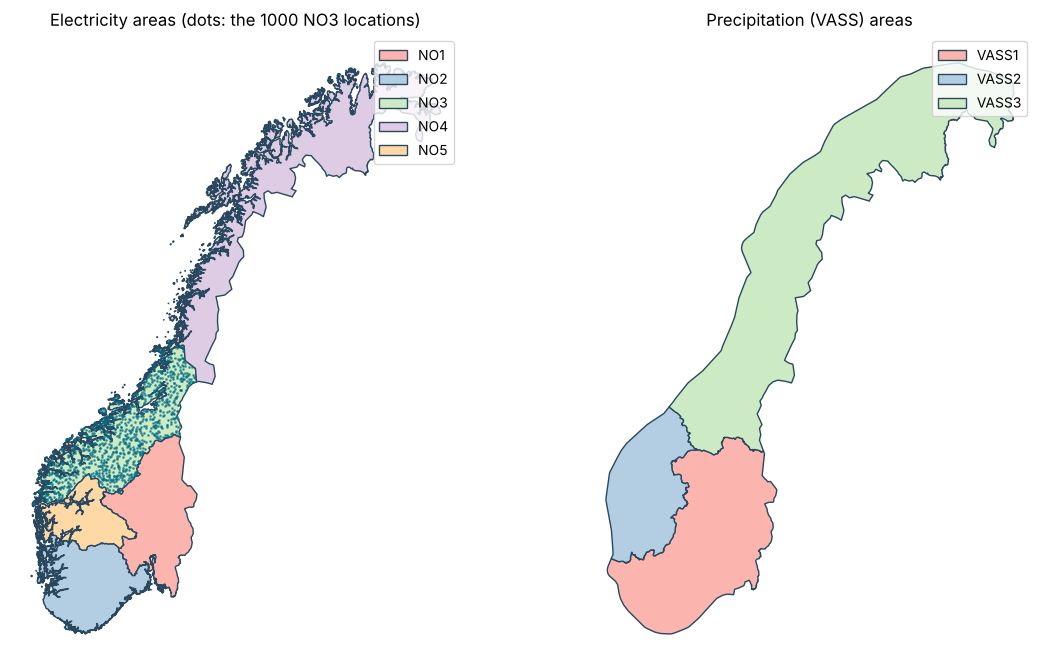

{
  "sources": {
    "electricity": "https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8",
    "administrative": "https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon/MapServer/0"
  },
  "seed": 320,
  "points_per_region": 1000,
  "sampling_crs": "EPSG:3035",
  "vass_regions": {
    "VASS1": [
      "RS",
      "RØ"
    ],
    "VASS2": [
      "RV"
    ],
    "VASS3": [
      "RM",
      "RN"
    ]
  },
  "note": "VASS areas are built from NVE regions (an administrative approximation, not exact catchments)."
}


In [2]:
#load the saved polygons and the 1000 sampled locations per region
regions = gpd.read_file(ROOT / "data/regions/regions.geojson")
points = pd.read_csv(ROOT / "data/regions/points.csv")
display(points.groupby("region").size().rename("sampled locations").to_frame())

#every region must have 1000 points, and every point must lie inside its region
assert points.groupby("region").size().eq(1000).all()
for name, part in points.groupby("region"):
    inside = gpd.GeoSeries(gpd.points_from_xy(part.longitude, part.latitude), crs=4326).within(
        regions.set_index("region").loc[name].geometry)
    assert inside.all(), name

#map of all regions, with the no3 sample highlighted
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, kinds, title in [(axes[0], ["NO1", "NO2", "NO3", "NO4", "NO5"], "Electricity areas"),
                         (axes[1], ["VASS1", "VASS2", "VASS3"], "Precipitation (VASS) areas")]:
    regions.loc[regions.region.isin(kinds)].to_crs(3035).plot(ax=ax, column="region", legend=True,
                                                              cmap="Pastel1", edgecolor="#29485f")
    ax.set_title(title)
    ax.set_axis_off()
no3_points = points.loc[points.region == REGION]
gpd.GeoSeries(gpd.points_from_xy(no3_points.longitude, no3_points.latitude), crs=4326).to_crs(3035).plot(
    ax=axes[0], markersize=1, color="#086e87", alpha=.6)
axes[0].set_title("Electricity areas (dots: the 1000 NO3 locations)")
fig.tight_layout()
plt.show()
print((ROOT / "data/regions/provenance.json").read_text())

## 3. ERA5 download and data quality

`download_region(region, start, end)` takes a region identifier and a time interval, looks up the list of (longitude, latitude) pairs for that region in `data/regions/points.csv`, and downloads hourly ERA5 reanalysis from the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (ERA5 is selected explicitly with `models=era5`). It returns the hourly mean over all locations.

By default, the function downloads eight variables: temperature and precipitation, plus rain, snowfall, relative humidity, wind speed, wind gusts and cloud cover, which are relevant for reservoir inflow (rain versus snow storage) and for later parts of the project. Every response is checked for units, complete hourly coverage (8784 hours in the leap year 2024), duplicates and missing values.

A full year at one location costs about 26 Open-Meteo call units, and the free limit is 10 000 per day, so the 1000-point NO3 download had to be spread over several hours. Each location is therefore cached as its own file, and an interrupted run continues where it stopped. The NO3 2024 experiment was downloaded with the two core variables. Running the cell below reuses the local cache and makes no new requests. The point cache is not stored on GitHub (about 95 MB), so without it the saved regional mean is read instead.

Source: Open-Meteo, ERA5 / Copernicus, CC BY 4.0. Neighbouring sampled points often share the same ERA5 grid cell (about 25–30 km), so the locations are not independent measurements.

In [3]:
#apply the download function to no3 for 2024 with the two core variables
print(json.dumps(estimate_download(START, END, 1000, CORE_VARIABLES), indent=2))
cache = WEATHER_DIR / f"{REGION}_{START}_{END}_{coordinates_fingerprint(load_points(REGION))}"
saved_mean, weather_metadata = load_region(REGION, START, END)
if cache.exists():
    #all 1000 locations are cached locally, so this only reads files and recomputes the mean
    weather = download_region(REGION, START, END, approved=True, variables=CORE_VARIABLES)
    print("cached locations:", len(list(cache.glob("point_*.parquet"))))
    print("max difference to the saved mean:", float((weather - saved_mean).abs().max().max()))
else:
    weather = saved_mean
    print("point cache not available; using the saved 1000 point mean")
print(json.dumps(weather_metadata, indent=2))

#quality checks: complete leap year, unique hours and no missing values
assert len(weather) == 8784 and weather.index.is_unique
assert np.isfinite(weather.to_numpy()).all()
display(weather.describe())
display(weather.head())

{
  "points": 1000,
  "hours_per_point": 8784,
  "variables": 2,
  "values": 17568000,
  "float32_MB": 70.27,
  "estimated_api_call_units": 26142.9
}


cached locations: 1000
max difference to the saved mean: 0.0
{
  "region": "NO3",
  "start": "2024-01-01",
  "end": "2024-12-31",
  "points": 1000,
  "complete_1000": true,
  "variables": [
    "temperature_2m",
    "precipitation"
  ],
  "model": "era5",
  "timezone": "UTC",
  "coordinates_hash": "ee8ea47e1fc6",
  "source": "https://archive-api.open-meteo.com/v1/archive",
  "point_cache": "NO3_2024-01-01_2024-12-31_ee8ea47e1fc6"
}


,temperature_2m,precipitation
count,8784.000000,8784.000000
mean,4.238217,0.197329
std,7.659723,0.283680
min,-16.737800,0.000000
25%,-0.817300,0.009700
50%,3.846300,0.084200
75%,10.041925,0.273600
max,24.328100,3.376700


,temperature_2m,precipitation
timestamp,,
2024-01-01 00:00:00+00:00,-6.0342,0.0059
2024-01-01 01:00:00+00:00,-6.1923,0.0050
2024-01-01 02:00:00+00:00,-6.1487,0.0050
2024-01-01 03:00:00+00:00,-6.1830,0.0050
2024-01-01 04:00:00+00:00,-6.1134,0.0048


### All eight variables for a smaller regional sample

The same API is used by `download_sample()` in the Streamlit app: the first *n* of the 1000 random locations are requested in one call and averaged. Here five NO3 locations are downloaded with all eight variables (about 130 call units).

In [4]:
#download all eight variables for five of the sampled no3 locations (requires internet access)
import requests
try:
    sample, sample_metadata = download_sample(REGION, START, END, n_points=5, variables=VARIABLES)
    display(sample.describe().T)
    print("returned ERA5 grid cells:", sample_metadata["grid_cells"])
except requests.RequestException as error:
    print("Open-Meteo could not be reached:", error)

Open-Meteo could not be reached: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=61.839113%2C64.450883%2C61.942779%2C61.157461%2C61.701506&longitude=6.848035%2C12.917140%2C8.227632%2C5.389852%2C8.311852&start_date=2024-01-01&end_date=2024-12-31&hourly=temperature_2m%2Cprecipitation%2Crain%2Csnowfall%2Crelative_humidity_2m%2Cwind_speed_10m%2Cwind_gusts_10m%2Ccloud_cover&models=era5&timezone=UTC&cell_selection=land (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


## 4. Precipitation outliers: DCT high-pass filter and robust SPC

`spc_analysis(series, cutoff_days=30, n_sigma=3)`:

1. An orthonormal DCT-II of the hourly mean precipitation; coefficient *k* has frequency *k*/(2*N*Δt).
2. All frequencies above 1/`cutoff_days` are set to zero; the inverse DCT gives a smooth seasonal baseline.
3. Original minus baseline gives the high-pass filtered, seasonally adjusted variations (SATV, called temperature variations in the assignment, here applied to precipitation as instructed).
4. The median and the median absolute deviation (MAD, scaled to be comparable with a standard deviation) of the SATV are computed over the whole year.
5. The SPC limits are baseline + median ± `n_sigma`·MAD, so they are drawn on the original precipitation scale. Hours outside the limits are outliers (red).

Only the precipitation, the two limit curves and the outliers are plotted; the SATV values themselves are not. Precipitation is skewed and often near zero, so the limits are descriptive rather than calibrated probabilities, and the negative lower limit has no physical meaning.

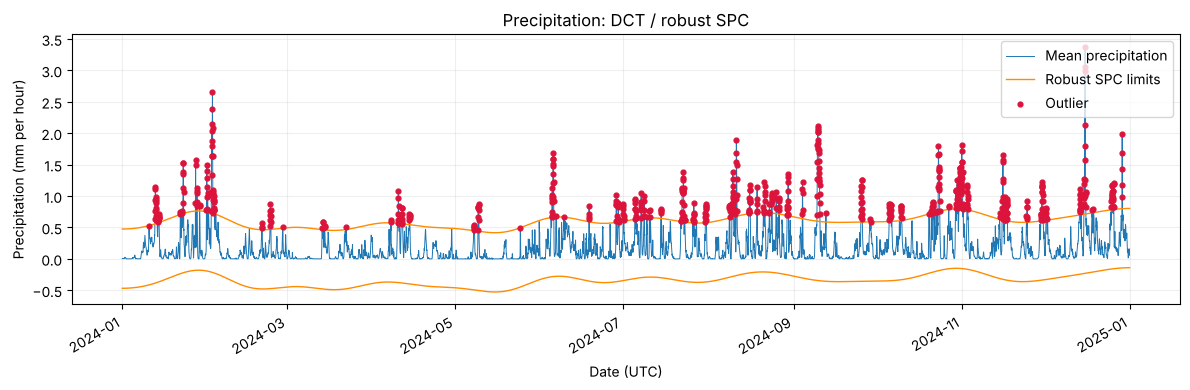

{'observations': 8784, 'outliers': 633, 'fraction': 0.07206284153005464, 'robust_sigma': 0.15724150253350103, 'zero_scale': False}


,value,baseline,lower,upper,outlier
timestamp,,,,,
2024-12-15 18:00:00+00:00,3.3767,0.307909,-0.230582,0.712867,True
2024-12-15 19:00:00+00:00,3.0607,0.308221,-0.230270,0.713179,True
2024-12-15 17:00:00+00:00,2.9963,0.307597,-0.230894,0.712555,True
2024-02-02 18:00:00+00:00,2.6633,0.322856,-0.215635,0.727814,True
2024-02-02 17:00:00+00:00,2.3918,0.323423,-0.215068,0.728381,True
2024-02-02 12:00:00+00:00,2.1478,0.326197,-0.212294,0.731155,True
2024-12-15 16:00:00+00:00,2.1363,0.307285,-0.231205,0.712244,True
2024-09-09 17:00:00+00:00,2.1167,0.193325,-0.345166,0.598283,True
2024-02-02 19:00:00+00:00,2.0897,0.322285,-0.216206,0.727243,True


,outlier hours
2024-10-31,24
2024-07-22,21
2024-06-05,19
2024-01-13,17
2024-10-23,16


In [5]:
#analyse precipitation with the default cutoff (30 days) and 3 robust standard deviations
CUTOFF_DAYS, N_SIGMA = 30, 3
fig, spc_table, spc_summary = spc_analysis(weather.precipitation, CUTOFF_DAYS, N_SIGMA)
plt.show()
print(spc_summary)

#the largest flagged hours, and the days with most outlier hours
display(spc_table.loc[spc_table.outlier].sort_values("value", ascending=False).head(10))
display(spc_table.loc[spc_table.outlier].groupby(spc_table.loc[spc_table.outlier].index.date).size()
        .sort_values(ascending=False).head(5).rename("outlier hours").to_frame())

## 5. Temperature anomalies: Local Outlier Factor

`lof_analysis(series, contamination=0.01, n_neighbors=48)` describes every hour with two standardized features: the temperature and its change since the previous hour (the first change is set to zero). LOF compares the density around each hour with the density around its 48 nearest neighbours, and the given proportion of hours with the lowest relative density (default 1%) is flagged. The proportion is an assumption, so the flagged hours are unusual, not necessarily wrong.

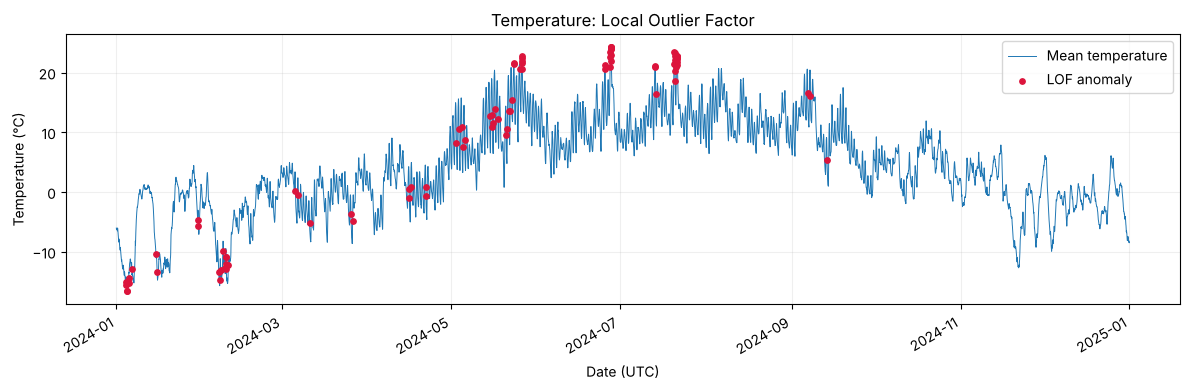

{'observations': 8784, 'outliers': 88, 'fraction': 0.010018214936247723}


,value,lof_score,outlier
timestamp,,,
2024-02-09 16:00:00+00:00,-11.9860,2.124686,True
2024-02-07 16:00:00+00:00,-13.1029,2.072824,True
2024-02-09 15:00:00+00:00,-10.8009,2.069047,True
2024-05-16 20:00:00+00:00,13.9061,2.032413,True
2024-03-25 18:00:00+00:00,-3.7058,1.882231,True
2024-04-21 19:00:00+00:00,0.7603,1.872662,True
2024-05-15 20:00:00+00:00,12.9215,1.870787,True
2024-05-22 06:00:00+00:00,13.6301,1.803361,True
2024-05-21 06:00:00+00:00,10.6111,1.778859,True


In [6]:
#identify temperature anomalies with the default proportion of 1%
fig, lof_table, lof_summary = lof_analysis(weather.temperature_2m, contamination=.01, n_neighbors=48)
plt.show()
print(lof_summary)
display(lof_table.loc[lof_table.outlier].sort_values("lof_score", ascending=False).head(10))

### Parameter sensitivity

Outlier counts depend on modelling choices. The following checks vary the DCT cutoff and the assumed LOF contamination while holding other defaults fixed. More flags do not establish worse data quality; they show sensitivity to the definition of an unusual observation.

In [7]:
#count flagged hours for other parameter choices (figures are closed, not shown)
sensitivity = []
for cutoff in [7, 30, 90]:
    figure, table, summary = spc_analysis(weather.precipitation, cutoff_days=cutoff, n_sigma=3)
    plt.close(figure)
    sensitivity.append({"method": "spc", "parameter": f"cutoff {cutoff} days", "flagged": summary["outliers"]})
for fraction in [.005, .01, .02]:
    figure, table, summary = lof_analysis(weather.temperature_2m, contamination=fraction, n_neighbors=48)
    plt.close(figure)
    sensitivity.append({"method": "lof", "parameter": f"proportion {100*fraction:g}%", "flagged": summary["outliers"]})
display(pd.DataFrame(sensitivity))

,method,parameter,flagged
0,spc,cutoff 7 days,640
1,spc,cutoff 30 days,633
2,spc,cutoff 90 days,725
3,lof,proportion 0.5%,44
4,lof,proportion 1%,88
5,lof,proportion 2%,176


## 6. Reservoir filling: a regular weekly series

The STL and spectrogram use the degree of filling (`fill_level`) of one reservoir area, EL 3 (= NO3), from the Magasinstatistikk data. A saved NVE snapshot keeps the notebook reproducible offline; the Streamlit app downloads the current data from the API. Missing weeks and duplicate dates are rejected rather than interpolated.

In [8]:
#select the no3 electricity area and check that every week is present
reservoir = pd.read_parquet(ROOT / "data/reservoir.parquet")
filling = weekly_series(reservoir, area_type="EL", area=3)
print("weekly observations:", len(filling))
print("time interval:", filling.index.min().date(), "to", filling.index.max().date())
print("step sizes:", filling.index.to_series().diff().dropna().value_counts().to_dict())
display(filling.describe())

weekly observations: 1660
time interval: 1995-01-08 to 2026-10-25
step sizes: {Timedelta('7 days 00:00:00'): 1659}


count    1660.000000
mean        0.597635
std         0.236924
min         0.107109
25%         0.391493
50%         0.640104
75%         0.801169
max         0.985538
Name: fill_level, dtype: float64

## 7. Seasonal-Trend decomposition using LOESS (STL)

`stl_analysis(series, seasonal=13, trend=105, robust=True)` splits the filling fraction into trend + seasonal component + residual with a period of 52 weeks. The seasonal smoother (13 weeks) controls how quickly the seasonal pattern may change from year to year, and the trend smoother (105 weeks ≈ two years) how smooth the trend is. Both must be odd, and the trend window must be longer than one period. Robust fitting reduces the influence of exceptional weeks.

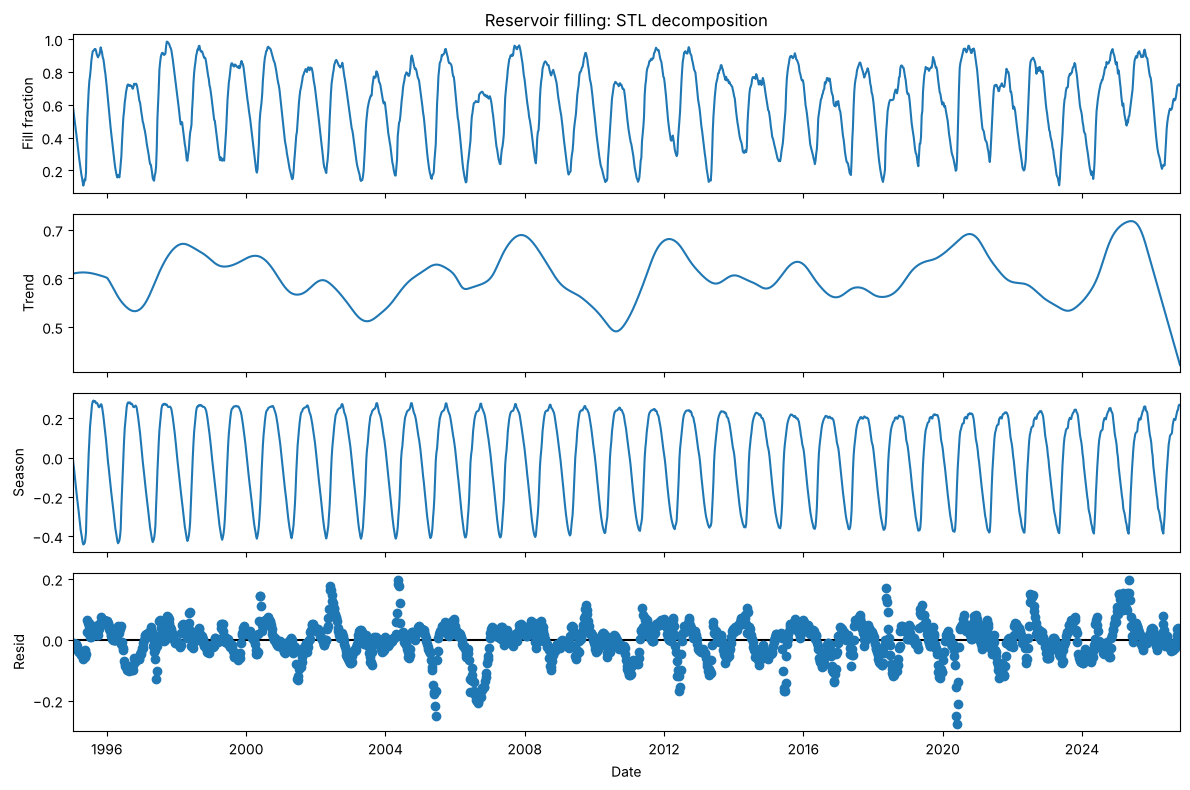

seasonal range: 0.733
residual standard deviation: 0.057


In [9]:
#decompose the whole weekly series and check that the three parts add up to the data
fig, stl_result = stl_analysis(filling, seasonal=13, trend=105, robust=True)
plt.show()
assert np.allclose(stl_result.trend + stl_result.seasonal + stl_result.resid, filling)
print("seasonal range:", round(float(stl_result.seasonal.max() - stl_result.seasonal.min()), 3))
print("residual standard deviation:", round(float(stl_result.resid.std()), 3))

## 8. Spectrogram of the same filling series

`spectrogram_analysis(series, window=156, overlap=130)` uses Hann windows of 156 weeks (three years) that overlap by 130 weeks; each window is linearly detrended. Frequencies are given in cycles per 52-week year, so 1 corresponds to the annual cycle. The frequency resolution is 52/156 = 1/3 cycle per year: longer windows separate frequencies better but show changes over time less precisely. The colour is the power density in dB; the plot shows 0–6 cycles per year.

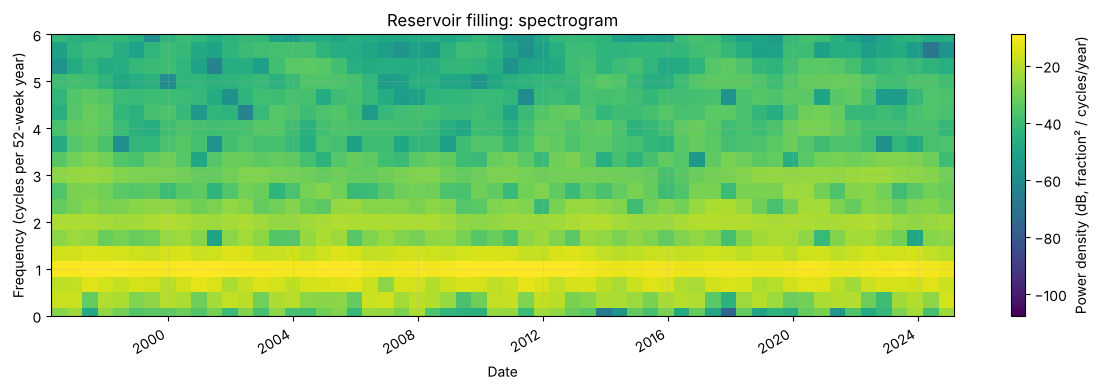

dominant nonzero frequency: 1.0 cycles per year


In [10]:
#use exactly the same weekly filling series as the stl analysis
fig, spectrum = spectrogram_analysis(filling, window=156, overlap=130)
plt.show()

#average power per frequency over all windows, ignoring the zero frequency
nonzero = spectrum["frequency"] > 0
frequency = spectrum["frequency"][nonzero]
mean_power = spectrum["power"][nonzero].mean(axis=1)
print("dominant nonzero frequency:", float(frequency[mean_power.argmax()]), "cycles per year")

## 9. Function tests

Besides the calls above, the functions are tested with `pytest` (folder `tests/`): known signals (an annual sine must give a spectral peak at 1 cycle per year, STL must recover a known seasonal pattern), injected outliers that SPC and LOF must find, constant series, invalid parameters and missing or irregular timestamps. Further tests cover the sampling, the VASS mapping, the downloader (cache reuse, quota stop, several locations in one request, unit checks) and the Streamlit pages, without network access or database writes.

In [11]:
#run the test suite (no network access and no database writes)
import subprocess
check = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"],
                       cwd=ROOT, capture_output=True, text=True)
print(check.stdout.replace(str(ROOT), "."))
if check.returncode:
    print(check.stderr)
assert check.returncode == 0

..........................................                               [100%]
42 passed in 20.92s



## 10. Interpretation of the actual results

In [12]:
#summarize the computed results in text
display(Markdown(f"""**Precipitation.** SPC flags **{spc_summary['outliers']}** of {len(weather)} hours ({spc_summary['fraction']:.1%}) with a 30-day baseline and three robust standard deviations. The flagged hours come in groups during heavy-rain episodes, mostly from July to January, while spring is quiet. Since precipitation is skewed, many hours exceed a symmetric limit, and the count changes with the cutoff, as the sensitivity table shows.

**Temperature.** LOF flags **{lof_summary['outliers']}** hours, the assumed 1%. They are mostly very cold hours in January and February and warm hours in May to July, together with hours of unusually fast temperature change.

**Reservoir filling.** The NO3 series has **{len(filling)} weekly observations**. STL shows a strong and stable annual cycle (seasonal range about {float(stl_result.seasonal.max() - stl_result.seasonal.min()):.2f} of the capacity), while the trend varies between dry and wet years. The spectrogram confirms the annual cycle as the dominant frequency (**{frequency[mean_power.argmax()]:.2f} cycles per year**) throughout the period, with weaker harmonics at 2 and 3 cycles per year.

Neither SPC nor LOF proves a data error; both point out hours that deserve a closer look. Averaging over 1000 locations also smooths out local extremes."""))

**Precipitation.** SPC flags **633** of 8784 hours (7.2%) with a 30-day baseline and three robust standard deviations. The flagged hours come in groups during heavy-rain episodes, mostly from July to January, while spring is quiet. Since precipitation is skewed, many hours exceed a symmetric limit, and the count changes with the cutoff, as the sensitivity table shows.

**Temperature.** LOF flags **88** hours, the assumed 1%. They are mostly very cold hours in January and February and warm hours in May to July, together with hours of unusually fast temperature change.

**Reservoir filling.** The NO3 series has **1660 weekly observations**. STL shows a strong and stable annual cycle (seasonal range about 0.73 of the capacity), while the trend varies between dry and wet years. The spectrogram confirms the annual cycle as the dominant frequency (**1.00 cycles per year**) throughout the period, with weaker harmonics at 2 and 3 cycles per year.

Neither SPC nor LOF proves a data error; both point out hours that deserve a closer look. Averaging over 1000 locations also smooths out local extremes.

## 11. Streamlit app

The Streamlit app uses the same URL as in Parts 1 and 2. The pages are grouped as *Project* (overview), *Reservoirs* (Reservoir Data, Reservoir Plots, STL and Spectrogram), *Weather* (SPC and LOF) and *Electricity* (Part 2, MongoDB).

- **Area selection (global):** one sidebar selector (area type EL/NO/VASS and area number) is shared by all reservoir and weather pages and kept when switching pages.
- **Meteorological data:** the weather page translates the selected area into a region (for example EL 3 → NO3, VASS 3 → RM+RN) and downloads ERA5 data for it directly from Open-Meteo, hidden in the background and cached. By default, the mean of 5 of the 1000 sampled locations is used, since all 1000 points would take hours because of the API limits; the number of locations is an option, and for NO3 2024 the complete 1000-point mean from this notebook can be selected. The weather year is a local setting on that page.
- **STL and Spectrogram page:** `st.tabs()` with the STL decomposition (seasonal smoother, trend smoother, robust) and the spectrogram (window length, overlap).
- **SPC and LOF page:** `st.tabs()` with the outlier/SPC analysis (DCT cutoff, number of standard deviations) and the anomaly/LOF analysis (proportion of outliers, neighbours), each with plot, summary metrics and a table of flagged hours.
- **Part 2 feedback:** the Reservoir Data page has a date interval that filters both the overview and the dataset, the repository has separate folders for notebooks and reports, and a README describes the project.

## 12. Development log

Part 3 extends the existing reservoir and electricity application with regional weather data and time series analysis. I started by reviewing the Part 1 and Part 2 notebooks, the Streamlit pages and the Git history. The existing work already included direct NVE access, an ENTSO-E pipeline using Spark and Cassandra, and a MongoDB-backed electricity page, and these were kept. All Part 3 work was done in the `part3-development` branch and merged into `main` after the Part 2 peer review and feedback were finished.

The geographical part retrieves the official NVE electricity areas and NVE regions, saves them as GeoJSON and shapefiles, and samples 1000 random locations per region in an equal-area projection. The precipitation (VASS) areas are built from the NVE regions as in the assignment: east is RS+RØ, west is RV and north is RM+RN. The current NVE area list also mentions a VASS4, but the reservoir data only contain VASS1–3 and their capacities add up to the national total, which confirmed that VASS3 must cover both Midt and Nord.

Weather data come from the historical Open-Meteo endpoint with the ERA5 model selected explicitly. The download function checks units, hourly coverage, duplicates and missing values. Because a year of hourly data counts as about 26 API calls per location, the 1000-point NO3 experiment had to respect the hourly and daily limits. Each location is cached separately so the download could pause and continue. The regional mean was checked against all cached points. The function now downloads eight variables by default, and several locations can be requested in one call.

Four reusable analysis functions were written for both the notebook and Streamlit: DCT/SPC for precipitation outliers, LOF for temperature anomalies, and STL and a spectrogram for the weekly reservoir filling. They were tested with synthetic signals with known answers, such as an injected spike and an annual sine wave.

In Streamlit, the biggest design question was how the weather data should follow the reservoir area selector. The final solution translates the selected area into a region and downloads a small random sample of its locations in the background, with caching, so no separate download page is needed. The two new pages use `st.tabs()`, and the pages are grouped by topic in the sidebar. The Part 2 feedback was addressed with a date interval on the Reservoir Data page, notebook and report folders and a README.

The main lessons were that API limits strongly affect the design of a data pipeline, and that reading the data carefully (here, the VASS areas) is as important as the analysis methods.

## 13. AI usage

OpenAI ChatGPT (including its Codex coding agent) served as a supporting tool for implementation planning, API documentation research, Streamlit integration, and notebook preparation in Part 3. It was also used to assist with Python programming, as well as to refine the overall structure and documentation of the Jupyter Notebook and Streamlit application.

During Part 3, ChatGPT provided guidance when testing code locally using numerical checks, deterministic synthetic signals, real NVE data, and an ERA5 pilot. It assisted in structuring test logs to distinguish completed checks from pending external tasks, and offered advice on how to preserve the existing Spark, Cassandra, and MongoDB pipeline without rerunning database writes ensuring historical outputs were correctly documented rather than presented as newly verified results.

Afterwards, Anthropic Claude was used to review the delivery against the assignment text and the feedback from Parts 1 and 2. This review led to corrections of the VASS3 area (RM+RN), a live weather download in Streamlit that follows the area selector, more weather variables, more code comments and a tidier repository.

Every suggestion, API response, and data transformation was critically reviewed, adapted, and manually tested before being incorporated. This included verifying local test results and ensuring that the overall pipeline functionality remained intact.

The AI tools provided helpful input and feedback throughout the problem-solving process, but all final decisions, code implementation, testing, and evaluation of results remained entirely my own responsibility.

## 14. Sources

- NVE reservoir statistics: https://www.nve.no/energi/analyser-og-statistikk/om-magasinstatistikken/
- NVE Magasinstatistikk API (data and area list): https://biapi.nve.no/magasinstatistikk/swagger/index.html
- NVE maps: https://atlas.nve.no
- Electricity areas layer: https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8
- NVE regions layer: https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon/MapServer/0
- Open-Meteo Historical Weather API (ERA5, CC BY 4.0): https://open-meteo.com/en/docs/historical-weather-api
- Open-Meteo API limits: https://open-meteo.com/en/pricing

## Appendix: source code of the shared functions

These are the functions imported and used above (from `src/geography.py`, `src/weather.py` and `src/analysis.py`). Printing them keeps the PDF self-contained; the helper functions they call are in the same files in the repository.

In [13]:
#print the source code of the main functions used in this notebook
import inspect
from src.geography import sample_polygon, build_regions
from src.weather import download_points
for function in [sample_polygon, build_regions, download_points, download_region, download_sample,
                 spc_analysis, lof_analysis, stl_analysis, spectrogram_analysis]:
    print(inspect.getsource(function))

def sample_polygon(geometry, count=1000, seed=320, original_wgs84=None):
    """draw count uniformly distributed random points inside a polygon.

    geometry must be in the equal area projection epsg:3035, so that every
    square kilometre has the same chance of being chosen. rejection sampling is
    used: random points are drawn in the bounding box and only points inside
    the polygon are kept. the result is returned as longitude/latitude.
    """
    if count < 1 or geometry.is_empty:
        raise ValueError('Nonempty polygon and positive count required.')
    #a fixed seed makes the sample identical every time it is regenerated
    rng = np.random.default_rng(seed)
    xmin, ymin, xmax, ymax = geometry.bounds
    points = []
    for _ in range(10000):
        #draw a batch of candidates in the bounding box
        x = rng.uniform(xmin, xmax, max(1000, count * 2))
        y = rng.uniform(ymin, ymax, len(x))
        inside = contains_xy(geometry, x, y)
        accepted_x, accept